<a href="https://colab.research.google.com/github/jyothirmaij/Intermediate-Assessment-3/blob/main/Intermediate_assesment3_jyothirmai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load the datasets
train = pd.read_csv("/content/drive/MyDrive/DSA/cases study/kaggle_competition/train.csv")
test = pd.read_csv("/content/drive/MyDrive/DSA/cases study/kaggle_competition/test.csv")
sample_submission = pd.read_csv("/content/drive/MyDrive/DSA/cases study/kaggle_competition/sample_submission.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [ ]:
print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Training dataset shape: (94, 14)
Testing dataset shape: (41, 13)
Sample submission shape: (3, 2)


In [ ]:
train.head()

,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB


In [ ]:
train.describe()

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.00000,94.000000,94.000000,94.000000,94.000000,93.000000
mean,176.580106,110.130426,82.936383,52.687553,32.535000,25.425319,90.88766,51.667021,96.259043,104.765213,209.530426,2.624516
std,5.443278,4.028920,3.187515,2.226749,1.383418,1.439065,2.85098,1.185340,2.187660,2.486498,4.972997,0.315968
min,165.580000,102.710000,74.820000,46.500000,29.340000,21.480000,84.04000,48.700000,88.900000,99.300000,198.600000,2.030000
25%,172.187500,106.835000,80.217500,51.207500,31.605000,24.500000,88.66000,51.000000,94.725000,103.175000,206.350000,2.400000
50%,176.915000,110.070000,83.325000,52.475000,32.605000,25.480000,91.03500,51.600000,96.500000,104.950000,209.900000,2.600000
75%,180.525000,113.252500,85.425000,54.347500,33.460000,26.372500,92.57000,52.475000,97.875000,106.550000,213.100000,2.830000
max,191.210000,119.480000,90.680000,58.360000,35.500000,28.700000,99.69000,54.700000,101.300000,112.200000,224.400000,3.530000


In [ ]:
# Count missing values in each column
print(train.isnull().sum())

id                  0
sexo                0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                1
dtype: int64


In [ ]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Duplicate IDs:", train["id"].duplicated().sum())

Duplicate IDs: 0


In [ ]:
print(train["sexo"].value_counts())

sexo
H    57
M    37
Name: count, dtype: int64


Exploratory Data Analysis (EDA)

sexo
H    57
M    37
Name: count, dtype: int64


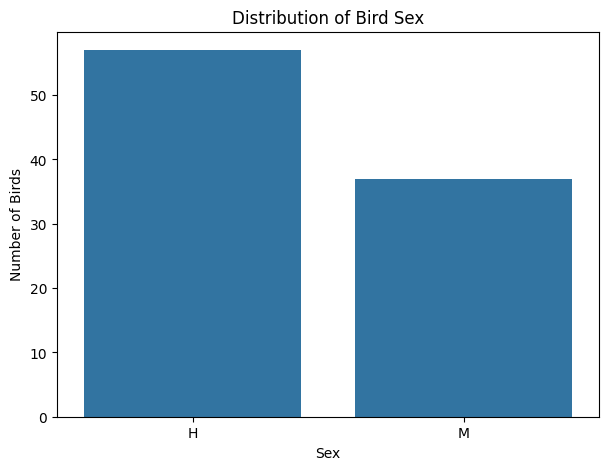

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the number of birds in each class
print(train["sexo"].value_counts())

# Visualize the class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=train, x="sexo")

plt.title("Distribution of Bird Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Birds")

plt.show()

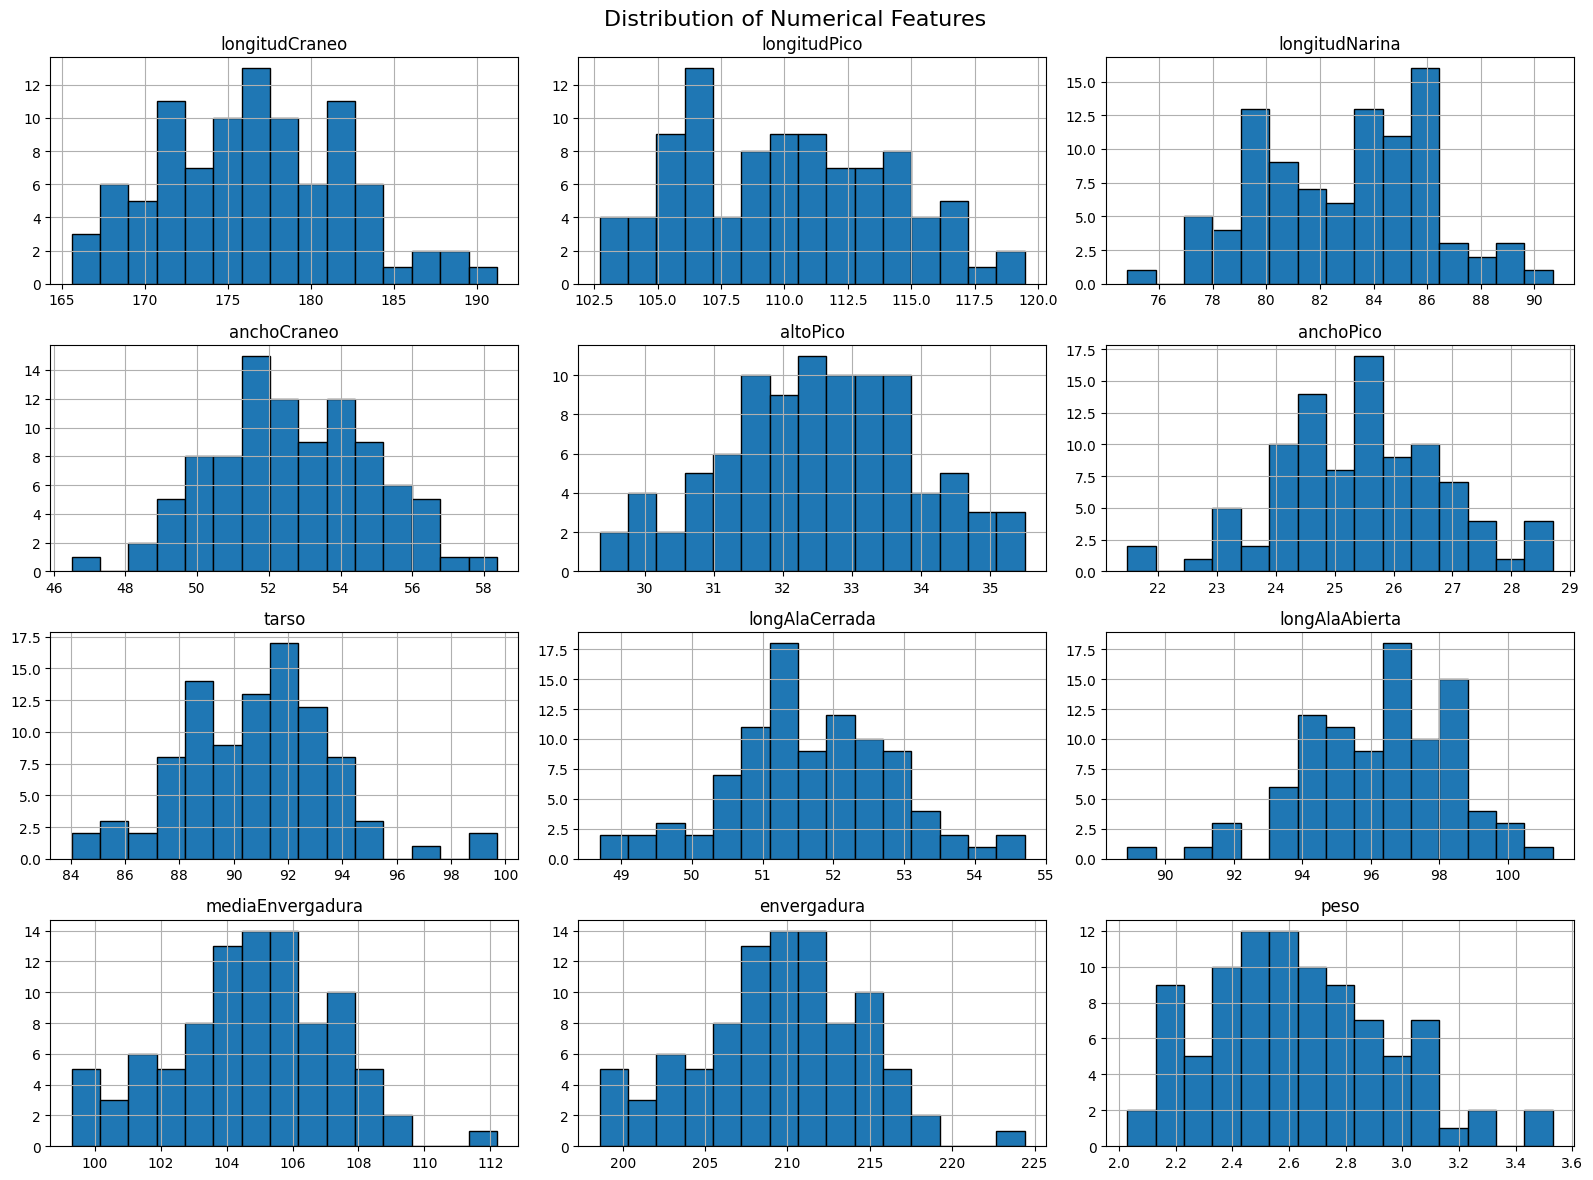

In [ ]:
# Select numerical features, excluding the ID and target
numerical_features = train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Create histograms
train[numerical_features].hist(
    figsize=(16, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

Compare weight between the two classes

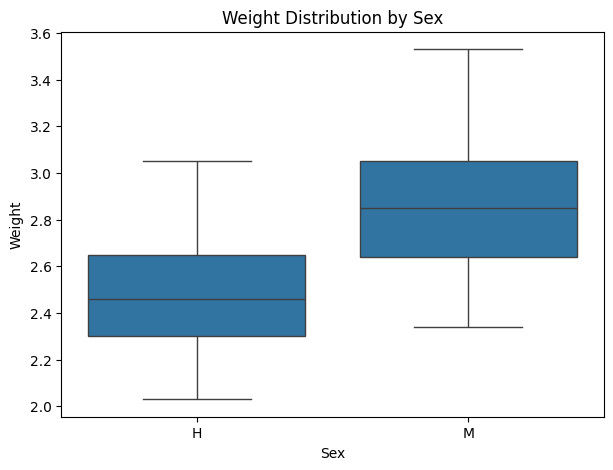

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=train,
    x="sexo",
    y="peso"
)

plt.title("Weight Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Weight")

plt.show()

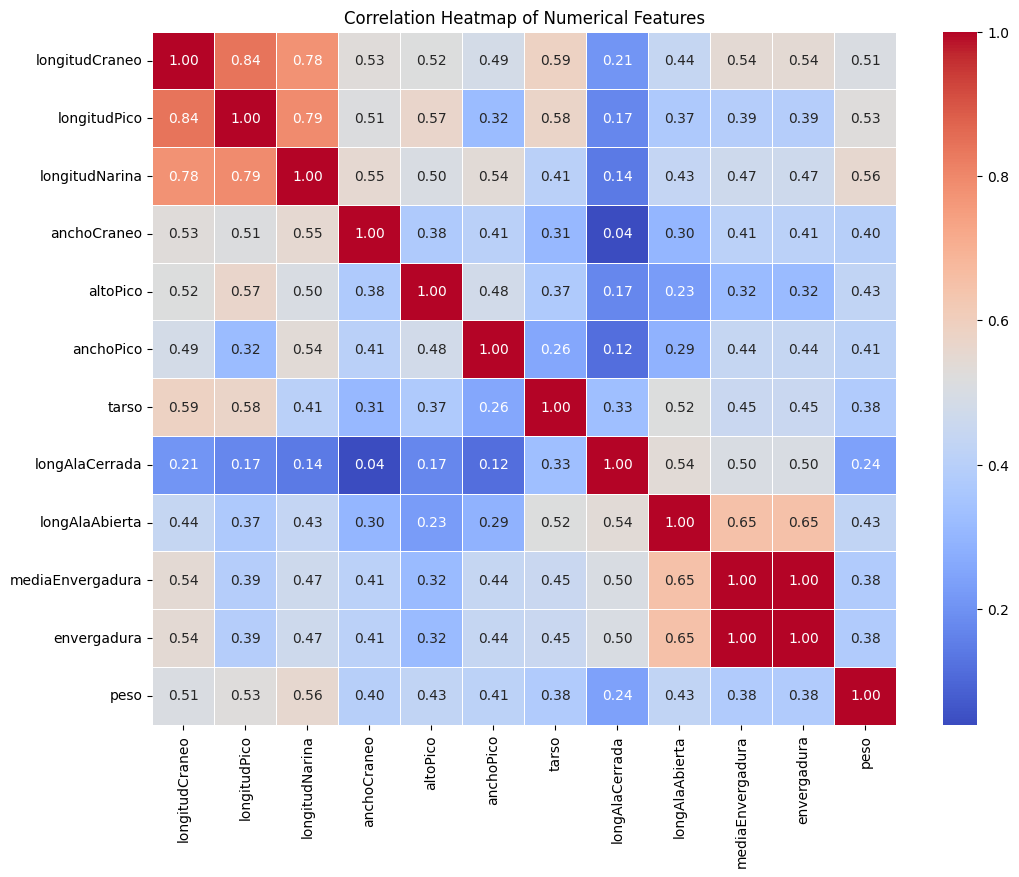

In [ ]:
# Calculate correlations between numerical features
correlation = train[numerical_features].corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Data Preprocessing

In [ ]:
# Separate input features and target variable

X = train.drop(columns=["id", "sexo"])
y = train["sexo"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature shape: (94, 12)
Target shape: (94,)

Feature columns:
['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

Training features: (75, 12)
Validation features: (19, 12)

Training target distribution:
sexo
H    45
M    30
Name: count, dtype: int64

Validation target distribution:
sexo
H    12
M     7
Name: count, dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# Train the Logistic Regression model

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict the validation data

y_pred = logistic_pipeline.predict(X_val)

print("Actual labels:")
print(y_val.values)

print("\nPredicted labels:")
print(y_pred)

Actual labels:
['M' 'H' 'H' 'H' 'H' 'M' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']

Predicted labels:
['M' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_val, y_pred)

print("Validation Accuracy:", round(accuracy, 4))
print("Validation Accuracy (%):", round(accuracy * 100, 2))

Validation Accuracy: 0.8947
Validation Accuracy (%): 89.47


In [ ]:
from sklearn.metrics import classification_report, f1_score

print("Classification Report:\n")

print(
    classification_report(
        y_val,
        y_pred,
        zero_division=0
    )
)

print("Weighted F1 Score:",
      round(f1_score(y_val, y_pred, average="weighted"), 4))

print("Macro F1 Score:",
      round(f1_score(y_val, y_pred, average="macro"), 4))

Classification Report:

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19

Weighted F1 Score: 0.8947
Macro F1 Score: 0.8869


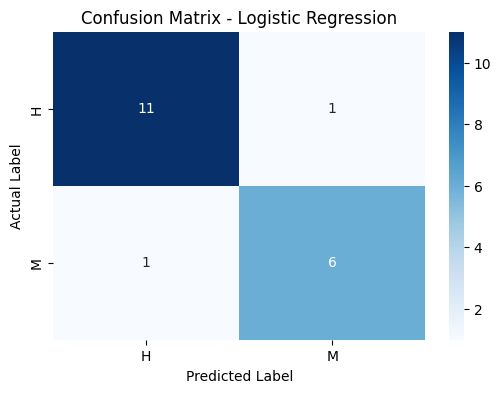

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=["H", "M"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["H", "M"],
    yticklabels=["H", "M"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

Train a Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [ ]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
rf_pred = rf_pipeline.predict(X_val)

print("Actual labels:")
print(y_val.values)

print("\nPredicted labels:")
print(rf_pred)

Actual labels:
['M' 'H' 'H' 'H' 'H' 'M' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']

Predicted labels:
['M' 'H' 'M' 'H' 'H' 'H' 'H' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

rf_accuracy = accuracy_score(y_val, rf_pred)

rf_weighted_f1 = f1_score(
    y_val,
    rf_pred,
    average="weighted"
)

rf_macro_f1 = f1_score(
    y_val,
    rf_pred,
    average="macro"
)

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest Accuracy (%):", round(rf_accuracy * 100, 2))
print("Weighted F1 Score:", round(rf_weighted_f1, 4))
print("Macro F1 Score:", round(rf_macro_f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_val, rf_pred, zero_division=0))

Random Forest Accuracy: 0.8421
Random Forest Accuracy (%): 84.21
Weighted F1 Score: 0.8392
Macro F1 Score: 0.8246

Classification Report:

              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



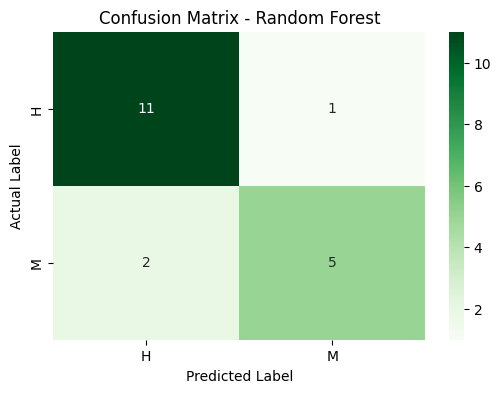

In [ ]:
cm_rf = confusion_matrix(
    y_val,
    rf_pred,
    labels=["H", "M"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["H", "M"],
    yticklabels=["H", "M"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Random Forest")

plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred)
    ],
    "Weighted F1": [
        f1_score(y_val, y_pred, average="weighted"),
        f1_score(y_val, rf_pred, average="weighted")
    ],
    "Macro F1": [
        f1_score(y_val, y_pred, average="macro"),
        f1_score(y_val, rf_pred, average="macro")
    ]
})

print(results.round(4))

                 Model  Accuracy  Weighted F1  Macro F1
0  Logistic Regression    0.8947       0.8947    0.8869
1        Random Forest    0.8421       0.8392    0.8246


Train a Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

print("SVM pipeline created successfully!")

SVM pipeline created successfully!


In [ ]:
svm_pipeline.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
svm_pred = svm_pipeline.predict(X_val)

print("Actual labels:")
print(y_val.values)

print("\nPredicted labels:")
print(svm_pred)

Actual labels:
['M' 'H' 'H' 'H' 'H' 'M' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']

Predicted labels:
['H' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

svm_accuracy = accuracy_score(y_val, svm_pred)

svm_weighted_f1 = f1_score(
    y_val,
    svm_pred,
    average="weighted"
)

svm_macro_f1 = f1_score(
    y_val,
    svm_pred,
    average="macro"
)

print("SVM Accuracy:", round(svm_accuracy, 4))
print("SVM Accuracy (%):", round(svm_accuracy * 100, 2))
print("SVM Weighted F1:", round(svm_weighted_f1, 4))
print("SVM Macro F1:", round(svm_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, svm_pred, zero_division=0))

SVM Accuracy: 0.8421
SVM Accuracy (%): 84.21
SVM Weighted F1: 0.8392
SVM Macro F1: 0.8246

Classification Report:
              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, svm_pred)
    ],
    "Weighted F1": [
        f1_score(y_val, y_pred, average="weighted"),
        f1_score(y_val, rf_pred, average="weighted"),
        f1_score(y_val, svm_pred, average="weighted")
    ],
    "Macro F1": [
        f1_score(y_val, y_pred, average="macro"),
        f1_score(y_val, rf_pred, average="macro"),
        f1_score(y_val, svm_pred, average="macro")
    ]
})

print(results.round(4).sort_values(
    by="Weighted F1",
    ascending=False
))

                 Model  Accuracy  Weighted F1  Macro F1
0  Logistic Regression    0.8947       0.8947    0.8869
1        Random Forest    0.8421       0.8392    0.8246
2                  SVM    0.8421       0.8392    0.8246


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_pipeline.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
# Predict validation data
knn_pred = knn_pipeline.predict(X_val)

print("Actual labels:")
print(y_val.values)

print("\nKNN predictions:")
print(knn_pred)

Actual labels:
['M' 'H' 'H' 'H' 'H' 'M' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']

KNN predictions:
['M' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

knn_accuracy = accuracy_score(y_val, knn_pred)

knn_weighted_f1 = f1_score(
    y_val,
    knn_pred,
    average="weighted"
)

knn_macro_f1 = f1_score(
    y_val,
    knn_pred,
    average="macro"
)

print("KNN Accuracy:", round(knn_accuracy, 4))
print("KNN Accuracy (%):", round(knn_accuracy * 100, 2))
print("KNN Weighted F1:", round(knn_weighted_f1, 4))
print("KNN Macro F1:", round(knn_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, knn_pred, zero_division=0))

KNN Accuracy: 0.8947
KNN Accuracy (%): 89.47
KNN Weighted F1: 0.8947
KNN Macro F1: 0.8869

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create Decision Tree pipeline
dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=3,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
dt_pipeline.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
# Predict validation data
dt_pred = dt_pipeline.predict(X_val)

print("Actual labels:")
print(y_val.values)

print("\nDecision Tree predictions:")
print(dt_pred)

Actual labels:
['M' 'H' 'H' 'H' 'H' 'M' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']

Decision Tree predictions:
['M' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [ ]:
dt_accuracy = accuracy_score(y_val, dt_pred)

dt_weighted_f1 = f1_score(
    y_val,
    dt_pred,
    average="weighted"
)

dt_macro_f1 = f1_score(
    y_val,
    dt_pred,
    average="macro"
)

print("Decision Tree Accuracy:", round(dt_accuracy, 4))
print("Decision Tree Accuracy (%):", round(dt_accuracy * 100, 2))
print("Decision Tree Weighted F1:", round(dt_weighted_f1, 4))
print("Decision Tree Macro F1:", round(dt_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, dt_pred, zero_division=0))

Decision Tree Accuracy: 0.8947
Decision Tree Accuracy (%): 89.47
Decision Tree Weighted F1: 0.8947
Decision Tree Macro F1: 0.8869

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



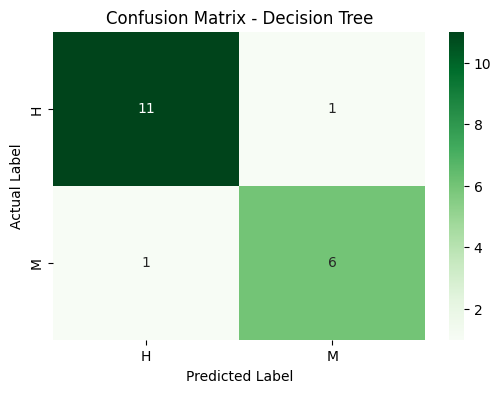

In [ ]:
cm_dt = confusion_matrix(
    y_val,
    dt_pred,
    labels=["H", "M"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["H", "M"],
    yticklabels=["H", "M"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Decision Tree")

plt.show()

In [ ]:
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM",
        "KNN",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, svm_pred),
        accuracy_score(y_val, knn_pred),
        accuracy_score(y_val, dt_pred)
    ],
    "Weighted F1": [
        f1_score(y_val, y_pred, average="weighted"),
        f1_score(y_val, rf_pred, average="weighted"),
        f1_score(y_val, svm_pred, average="weighted"),
        f1_score(y_val, knn_pred, average="weighted"),
        f1_score(y_val, dt_pred, average="weighted")
    ],
    "Macro F1": [
        f1_score(y_val, y_pred, average="macro"),
        f1_score(y_val, rf_pred, average="macro"),
        f1_score(y_val, svm_pred, average="macro"),
        f1_score(y_val, knn_pred, average="macro"),
        f1_score(y_val, dt_pred, average="macro")
    ]
})

results_df = results_df.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                 Model  Accuracy  Weighted F1  Macro F1
0  Logistic Regression    0.8947       0.8947    0.8869
1        Decision Tree    0.8947       0.8947    0.8869
2                  KNN    0.8947       0.8947    0.8869
3                  SVM    0.8421       0.8392    0.8246
4        Random Forest    0.8421       0.8392    0.8246


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully!")

Gradient Boosting pipeline created successfully!


In [ ]:
# Train Gradient Boosting on the training set
gb_pipeline.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [ ]:
# Predict the validation set
gb_pred = gb_pipeline.predict(X_val)

print("Actual labels:")
print(y_val.values)

print("\nGradient Boosting predictions:")
print(gb_pred)

Actual labels:
['M' 'H' 'H' 'H' 'H' 'M' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']

Gradient Boosting predictions:
['M' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

gb_accuracy = accuracy_score(y_val, gb_pred)

gb_weighted_f1 = f1_score(
    y_val,
    gb_pred,
    average="weighted"
)

gb_macro_f1 = f1_score(
    y_val,
    gb_pred,
    average="macro"
)

print("Gradient Boosting Accuracy:", round(gb_accuracy, 4))
print("Gradient Boosting Accuracy (%):", round(gb_accuracy * 100, 2))
print("Weighted F1 Score:", round(gb_weighted_f1, 4))
print("Macro F1 Score:", round(gb_macro_f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_val, gb_pred, zero_division=0))

Gradient Boosting Accuracy: 0.8947
Gradient Boosting Accuracy (%): 89.47
Weighted F1 Score: 0.8947
Macro F1 Score: 0.8869

Classification Report:

              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



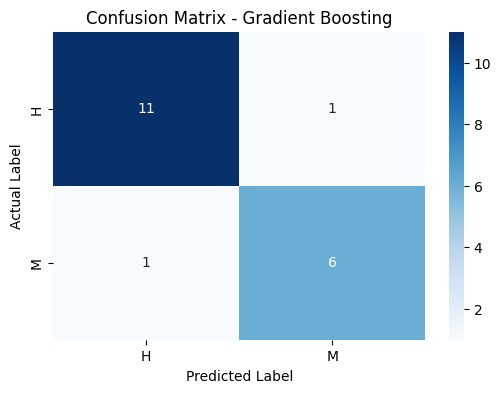

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_gb = confusion_matrix(
    y_val,
    gb_pred,
    labels=["H", "M"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["H", "M"],
    yticklabels=["H", "M"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Gradient Boosting")

plt.show()

In [ ]:
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "SVM",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, dt_pred),
        accuracy_score(y_val, knn_pred),
        accuracy_score(y_val, svm_pred),
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, gb_pred)
    ],
    "Weighted F1": [
        f1_score(y_val, y_pred, average="weighted"),
        f1_score(y_val, dt_pred, average="weighted"),
        f1_score(y_val, knn_pred, average="weighted"),
        f1_score(y_val, svm_pred, average="weighted"),
        f1_score(y_val, rf_pred, average="weighted"),
        f1_score(y_val, gb_pred, average="weighted")
    ],
    "Macro F1": [
        f1_score(y_val, y_pred, average="macro"),
        f1_score(y_val, dt_pred, average="macro"),
        f1_score(y_val, knn_pred, average="macro"),
        f1_score(y_val, svm_pred, average="macro"),
        f1_score(y_val, rf_pred, average="macro"),
        f1_score(y_val, gb_pred, average="macro")
    ]
})

results_df = results_df.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                 Model  Accuracy  Weighted F1  Macro F1
0  Logistic Regression    0.8947       0.8947    0.8869
1        Decision Tree    0.8947       0.8947    0.8869
2                  KNN    0.8947       0.8947    0.8869
3    Gradient Boosting    0.8947       0.8947    0.8869
4                  SVM    0.8421       0.8392    0.8246
5        Random Forest    0.8421       0.8392    0.8246


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Models to compare
models_to_compare = {
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": dt_pipeline,
    "KNN": knn_pipeline,
    "Gradient Boosting": gb_pipeline,
    "SVM": svm_pipeline,
    "Random Forest": rf_pipeline
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "weighted_f1": "f1_weighted",
    "macro_f1": "f1_macro"
}

results = []

for name, model in models_to_compare.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Weighted F1": scores["test_weighted_f1"].mean(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Accuracy Std": scores["test_accuracy"].std()
    })

cv_results_df = pd.DataFrame(results)

cv_results_df = cv_results_df.sort_values(
    by="Mean Weighted F1",
    ascending=False
).reset_index(drop=True)

print(cv_results_df.round(4))

                 Model  Mean Accuracy  Mean Weighted F1  Mean Macro F1  \
0                  SVM         0.8918            0.8927         0.8891   
1                  KNN         0.8702            0.8715         0.8672   
2        Random Forest         0.8708            0.8712         0.8648   
3  Logistic Regression         0.8602            0.8574         0.8484   
4        Decision Tree         0.8386            0.8393         0.8345   
5    Gradient Boosting         0.8392            0.8380         0.8283   

   Accuracy Std  
0        0.0933  
1        0.1096  
2        0.1018  
3        0.0766  
4        0.1202  
5        0.0917  


In [ ]:
# Import necessary libraries
from sklearn.base import clone

# Separate features and target from the complete training dataset
X_full = train.drop(columns=["id", "sexo"])
y_full = train["sexo"]

# Prepare test features
X_test = test.drop(columns=["id"])

# Create a fresh copy of the SVM pipeline
final_model = clone(svm_pipeline)

# Train using all available labelled data
final_model.fit(X_full, y_full)

print("SVM trained successfully!")
print("Training data shape:", X_full.shape)
print("Test data shape:", X_test.shape)

SVM trained successfully!
Training data shape: (94, 12)
Test data shape: (41, 12)


In [ ]:
# Predict the sex of the albatrosses in the test dataset
test_predictions = final_model.predict(X_test)

# Display the predictions
print("Predictions:")
print(test_predictions)

# Count predictions for each class
import pandas as pd

print("\nPrediction distribution:")
print(pd.Series(test_predictions).value_counts())

Predictions:
['M' 'H' 'M' 'M' 'M' 'M' 'H' 'M' 'M' 'M' 'H' 'H' 'H' 'M' 'H' 'H' 'H' 'H'
 'H' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'H' 'H'
 'H' 'H' 'M' 'M' 'M']

Prediction distribution:
M    21
H    20
Name: count, dtype: int64


In [ ]:
print("Sample submission:")
display(sample_submission)

print("Sample submission columns:", sample_submission.columns.tolist())
print("Test dataset columns:", test.columns.tolist())

Sample submission:


,id,sexo
0,id_1,M
1,id_2,H
2,id_3,M


Sample submission columns: ['id', 'sexo']
Test dataset columns: ['id', 'longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']


In [ ]:
# Create submission dataframe
submission = pd.DataFrame({
    "id": test["id"],
    "sexo": test_predictions
})

# Match the exact sample submission column order
submission = submission[sample_submission.columns]

# Validate the submission
print("Submission shape:", submission.shape)
print("\nFirst 5 predictions:")
display(submission.head())

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPredicted classes:")
print(submission["sexo"].value_counts())

# Save the file
submission.to_csv("submission.csv", index=False)

print("\nSubmission file created successfully!")

Submission shape: (41, 2)

First 5 predictions:


,id,sexo
0,A70_2018,M
1,5C9_2018,H
2,5E1_2018,M
3,C58_2018,M
4,5E2_2018,M



Missing values:
id      0
sexo    0
dtype: int64

Predicted classes:
sexo
M    21
H    20
Name: count, dtype: int64

Submission file created successfully!


In [ ]:
from google.colab import files

files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>